In [11]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


# House Prices: Advanced Regression Techniques
## Xây dựng và so sánh các mô hình hồi quy dự đoán giá nhà

**Mục tiêu:** dự đoán `SalePrice` từ các đặc trưng của ngôi nhà. Đây là bài toán **Regression**, không phải Classification.

In [12]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Đọc dữ liệu

In [13]:
possible_dirs = [
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
    "/kaggle/input/house-prices-advanced-regression-techniques", "."
]

data_dir = next(
    (d for d in possible_dirs
     if os.path.exists(os.path.join(d, "train.csv"))
     and os.path.exists(os.path.join(d, "test.csv"))),
    None
)

if data_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy train.csv và test.csv. "
        "Trên Kaggle hãy Add Input cuộc thi House Prices; "
        "nếu chạy local, đặt hai file CSV cùng thư mục notebook."
    )

train = pd.read_csv(os.path.join(data_dir, "train.csv"))
test = pd.read_csv(os.path.join(data_dir, "test.csv"))

print("Train shape:", train.shape)
print("Test shape:", test.shape)
display(train.head())

Train shape: (1460, 81)
Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Khám phá dữ liệu (EDA)

Kích thước train: (1460, 81)
Kiểu dữ liệu:


,Số thuộc tính
Data type,
object,43
int64,35
float64,3


Số lượng giá trị thiếu nhiều nhất:


,Missing values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


Thống kê biến mục tiêu SalePrice:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

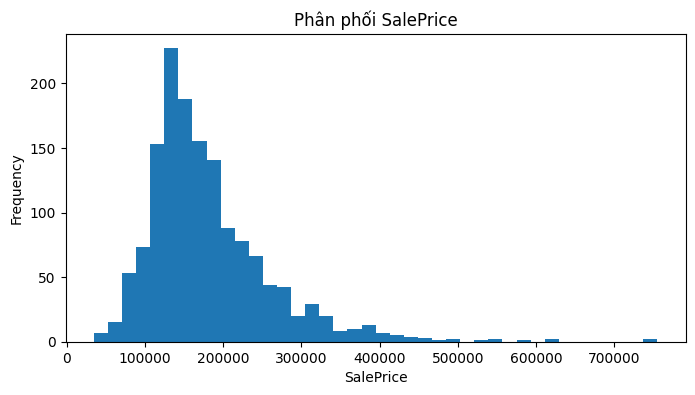

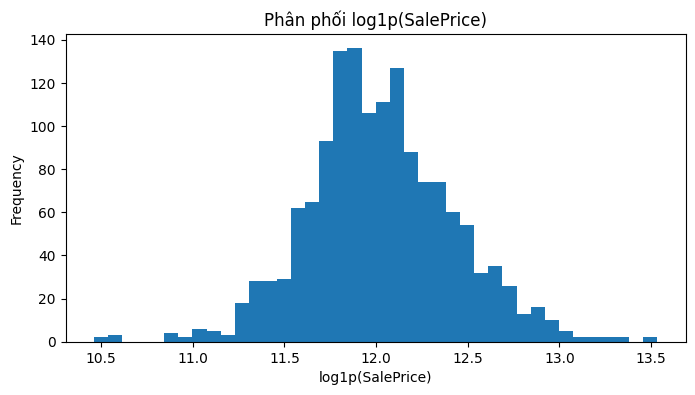

In [14]:
print("Kích thước train:", train.shape)
print("Kiểu dữ liệu:")
display(train.dtypes.value_counts().rename_axis("Data type").to_frame("Số thuộc tính"))

print("Số lượng giá trị thiếu nhiều nhất:")
display(train.isnull().sum().sort_values(ascending=False).head(20).to_frame("Missing values"))

print("Thống kê biến mục tiêu SalePrice:")
display(train["SalePrice"].describe())

plt.figure(figsize=(8, 4))
plt.hist(train["SalePrice"], bins=40)
plt.title("Phân phối SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(np.log1p(train["SalePrice"]), bins=40)
plt.title("Phân phối log1p(SalePrice)")
plt.xlabel("log1p(SalePrice)")
plt.ylabel("Frequency")
plt.show()

## 4. Chuẩn bị dữ liệu và chia tập Validation

In [15]:
TARGET = "SalePrice"
DROP_COLUMNS = ["Id"]

X = train.drop(columns=[TARGET] + DROP_COLUMNS, errors="ignore")
y = train[TARGET].copy()
X_test = test.drop(columns=DROP_COLUMNS, errors="ignore")

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Số mẫu train:", len(X_train))
print("Số mẫu validation:", len(X_valid))
print("Số thuộc tính số:", len(numeric_features))
print("Số thuộc tính phân loại:", len(categorical_features))

Số mẫu train: 1168
Số mẫu validation: 292
Số thuộc tính số: 36
Số thuộc tính phân loại: 43


## 5. Xây dựng các mô hình hồi quy

Huấn luyện ba mô hình:
1. Linear Regression.
2. Decision Tree Regressor.
3. Random Forest Regressor.

In [16]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

fitted_models = {}
results = []

def calculate_metrics(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    rmsle = np.sqrt(mean_squared_error(
        np.log1p(np.maximum(y_true, 0)),
        np.log1p(y_pred)
    ))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, rmsle, r2

for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", TransformedTargetRegressor(
            regressor=estimator,
            func=np.log1p,
            inverse_func=np.expm1
        ))
    ])

    model_pipeline.fit(X_train, y_train)
    valid_predictions = model_pipeline.predict(X_valid)

    mae, rmse, rmsle, r2 = calculate_metrics(y_valid, valid_predictions)

    fitted_models[model_name] = model_pipeline
    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSLE").reset_index(drop=True)
display(results_df.style.format({
    "MAE": "{:,.2f}", "RMSE": "{:,.2f}",
    "RMSLE": "{:.5f}", "R2": "{:.5f}"
}))

,Model,MAE,RMSE,RMSLE,R2
0,Linear Regression,"16,969.48","25,417.93",0.14195,0.91577
1,Random Forest Regressor,"16,987.06","29,117.67",0.14346,0.88947
2,Decision Tree Regressor,"25,529.45","42,825.65",0.19300,0.76089


## 6. So sánh và lựa chọn mô hình

Mô hình tốt nhất theo RMSLE validation: Linear Regression
RMSLE validation: 0.14194877002971043


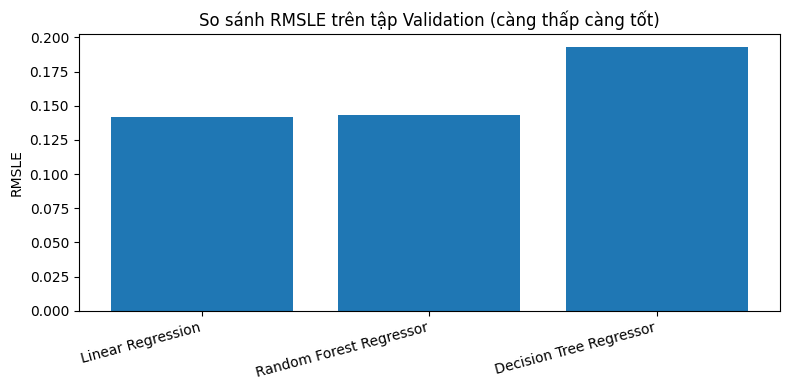

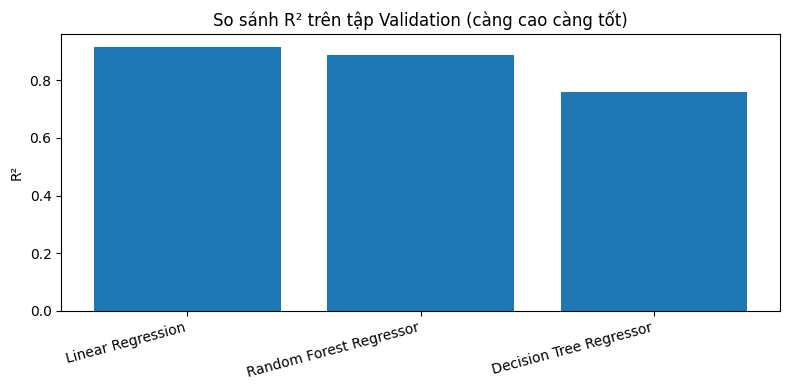

In [17]:
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]

print("Mô hình tốt nhất theo RMSLE validation:", best_model_name)
print("RMSLE validation:", results_df.loc[0, "RMSLE"])

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["RMSLE"])
plt.title("So sánh RMSLE trên tập Validation (càng thấp càng tốt)")
plt.ylabel("RMSLE")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("So sánh R² trên tập Validation (càng cao càng tốt)")
plt.ylabel("R²")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 7. Phân tích dự đoán trên Validation

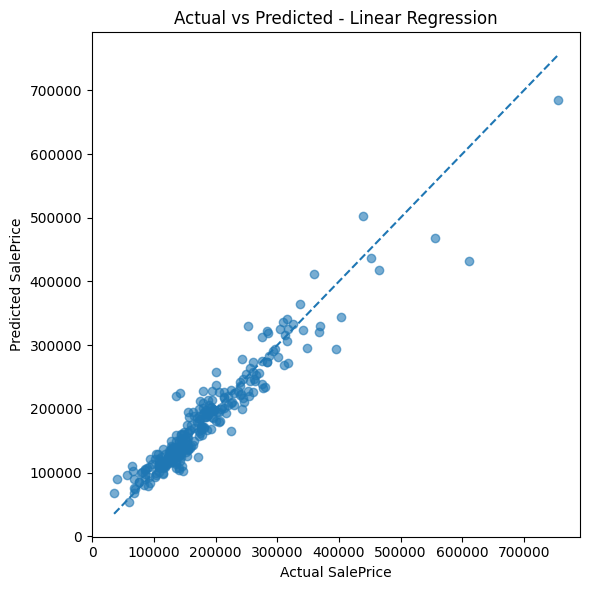

,Actual,Predicted,Absolute Error
892,154500,154179.972414,320.027586
1105,325000,333419.637160,8419.637160
413,115000,99772.037468,15227.962532
522,159000,166111.587205,7111.587205
1036,315500,340876.374423,25376.374423
614,75500,85522.413668,10022.413668
218,311500,269490.275849,42009.724151
1160,146000,142383.259317,3616.740683
649,84500,80358.350002,4141.649998
887,135500,137831.381533,2331.381533


In [18]:
valid_predictions = np.maximum(best_model.predict(X_valid), 0)

plt.figure(figsize=(6, 6))
plt.scatter(y_valid, valid_predictions, alpha=0.6)
min_value = min(y_valid.min(), valid_predictions.min())
max_value = max(y_valid.max(), valid_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.tight_layout()
plt.show()

valid_errors = pd.DataFrame({
    "Actual": y_valid,
    "Predicted": valid_predictions,
    "Absolute Error": np.abs(y_valid - valid_predictions)
})
display(valid_errors.head(10))

## 8. Huấn luyện lại trên toàn bộ tập Train và tạo Submission

In [19]:
best_model.fit(X, y)
test_predictions = np.maximum(best_model.predict(X_test), 0)

sample_submission_path = os.path.join(data_dir, "sample_submission.csv")
if os.path.exists(sample_submission_path):
    submission = pd.read_csv(sample_submission_path)
    submission[TARGET] = test_predictions
else:
    submission = pd.DataFrame({
        "Id": test["Id"],
        TARGET: test_predictions
    })

submission.to_csv("submission_house_prices.csv", index=False)
print("Đã tạo file: submission_house_prices.csv")
print("Số dòng dự đoán:", len(submission))
display(submission.head())

Đã tạo file: submission_house_prices.csv
Số dòng dự đoán: 1459


,Id,SalePrice
0,1461,115336.556591
1,1462,152497.476941
2,1463,171351.455463
3,1464,189205.507006
4,1465,203143.767148
